In [3]:
import os 
from pathlib import Path
from dotenv import load_dotenv
import numpy as np
import pandas as pd 
load_dotenv(override=True)

import matplotlib.pyplot as plt

In [4]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

gw5_xg_by_minute = DATA_REPO_DIR / "GW5" / "xg_by_minute.csv"
gw5_xg = pd.read_csv(gw5_xg_by_minute)

In [5]:
dfs = []

for gw in range(1,7):
    gw_xg_by_min = DATA_REPO_DIR / f"GW{gw}" / "xg_by_minute.csv"
    gw_xg = pd.read_csv(gw_xg_by_min)
    gw_xg["gameweek"] = gw

    is_tot = gw_xg["match_id"].apply(
        lambda x: "tottenham" in str(x).split("-")
    )
    dfs.append(gw_xg[is_tot])

gws_xg = pd.concat(dfs, ignore_index=True)

In [6]:
goals = []

for gw in range(1,7):
    gw_shots_by_min = DATA_REPO_DIR / f"GW{gw}" / "shots.csv"
    gw_shots = pd.read_csv(gw_shots_by_min)

    gw_shots = gw_shots[gw_shots["outcome"].isin(["goal"])]

    is_tot = gw_shots["match_id"].apply(
        lambda x: "tottenham" in str(x).split("-")
    )
    goals.append(gw_shots[is_tot])

gws_shots = pd.concat(goals, ignore_index=True)

In [7]:
drop_index = []
for shot in gws_shots.index:
    if (gws_shots.loc[shot, "match_id"].split("-")[3] == "tottenham") and (gws_shots["is_home"][shot] == False):
        drop_index.append(shot)
    elif (gws_shots.loc[shot, "match_id"].split("-")[3] != "tottenham") and (gws_shots["is_home"][shot] == True):
        drop_index.append(shot)

gws_shots.drop(drop_index, inplace=True)

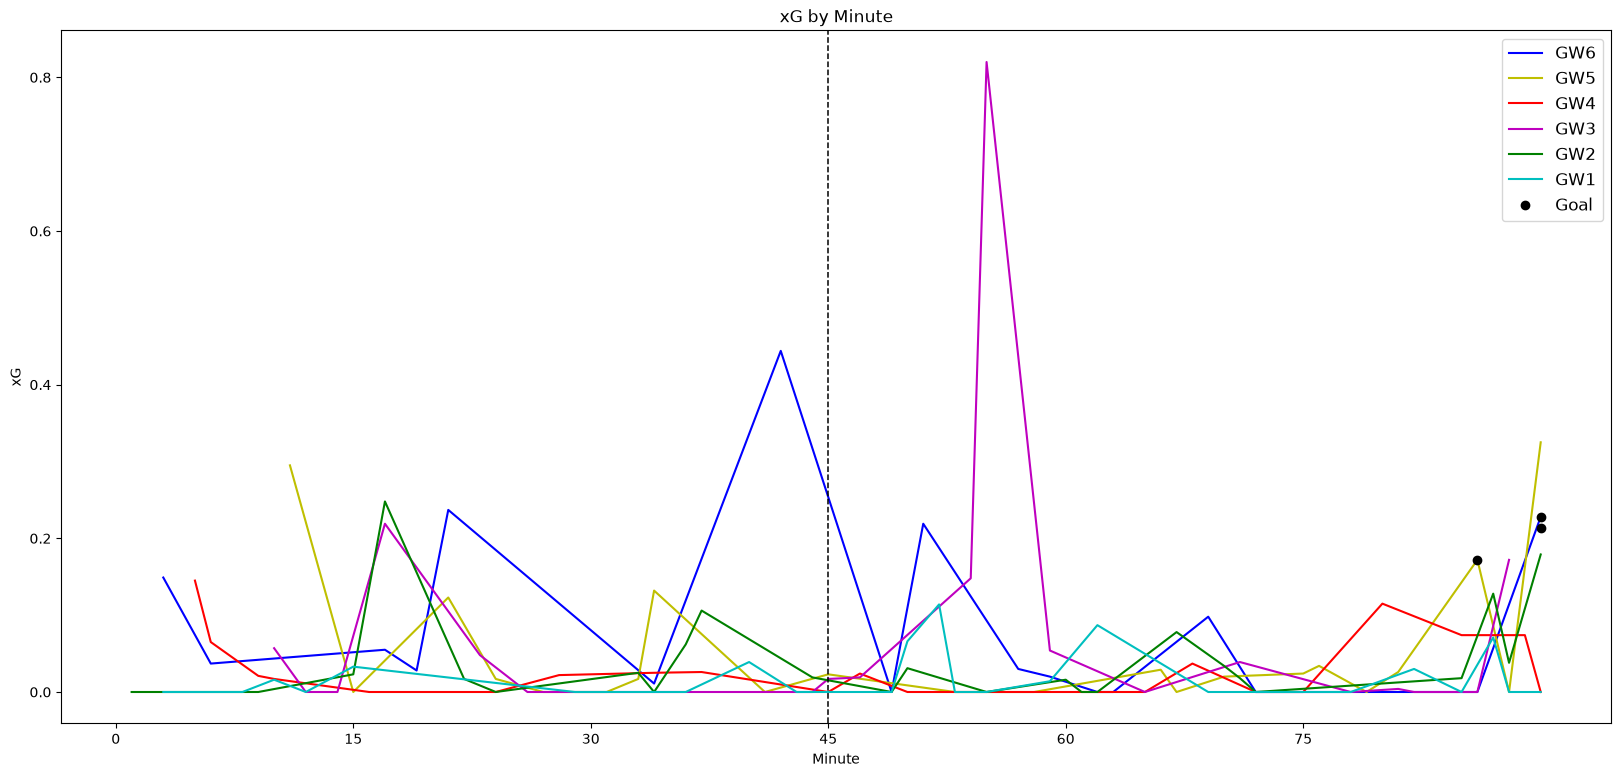

In [8]:
fig, ax = plt.subplots(figsize=(20, 9))
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 6], gws_xg["away_xg"][gws_xg["gameweek"] == 6], '-', color="b", label="GW6")
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 5], gws_xg["home_xg"][gws_xg["gameweek"] == 5], '-', color="y", label="GW5")
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 4], gws_xg["home_xg"][gws_xg["gameweek"] == 4], '-', color="r", label="GW4")
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 3], gws_xg["away_xg"][gws_xg["gameweek"] == 3], '-', color="m", label="GW3")
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 2], gws_xg["home_xg"][gws_xg["gameweek"] == 2], '-', color="g", label="GW2")
ax.plot(gws_xg["minute"][gws_xg["gameweek"] == 1], gws_xg["away_xg"][gws_xg["gameweek"] == 1], '-', color="c", label="GW1")

ax.plot(gws_shots["minute"], gws_shots["xg"], "o", color='k', label='Goal')

ax.axvline(x=45, color='k', linestyle='--', linewidth=1.1)
plt.legend(fontsize='large')
plt.title("xG by Minute")
plt.xlabel("Minute")
plt.ylabel("xG")
plt.xticks(np.arange(0, 90, 15))

plt.show()